In [ ]:
# Crear carpeta de destino
!mkdir -p /content/mi_dataset

# Descomprimir el archivo de forma segura
!unzip -q /content/dataset.zip -d /content/mi_dataset

# Listar el contenido extraído para verificar la estructura
!ls /content/mi_dataset

replace /content/mi_dataset/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: data.yaml  test  train	valid


In [ ]:
import yaml

yaml_path = '/content/mi_dataset/data.yaml'

# Leer el archivo actual
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

# Forzar las rutas correctas de Google Colab
data['path'] = '/content/mi_dataset'
data['train'] = 'train/images'
data['val'] = 'valid/images'   # Roboflow usa 'valid' en lugar de 'val'
data['test'] = 'test/images'

# Guardar los cambios
with open(yaml_path, 'w') as f:
    yaml.dump(data, f, default_flow_style=False)

print("¡Archivo data.yaml configurado con éxito para Colab!")


¡Archivo data.yaml configurado con éxito para Colab!


In [ ]:
!pip install ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.7 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

# Cargamos el modelo base Nano de nuevo
model = YOLO('yolo26n.pt')

# Iniciamos el entrenamiento maximizando la precisión del modelo ligero
results = model.train(
    data='/content/mi_dataset/data.yaml', # Corregido: La ruta del archivo data.yaml
    epochs=150,             # Más épocas para un aprendizaje más profundo
    imgsz=640,              # Resolución nativa óptima
    batch=16,               # Tamaño de lote estable para la T4
    optimizer='MuSGD',
    device=0,
    patience=30,            # Tolerancia de 30 épocas sin mejora antes de detenerse

    # --- AUMENTO DE DATOS CRÍTICO PARA EL ENTORNO DE LA RASPBERRY ---
    degrees=30.0,           # Rota las fotos hasta 30° (las hojas crecen en cualquier ángulo)
    fliplr=0.5,             # Volteo horizontal espejo
    flipud=0.5,             # Volteo vertical (esencial para cámaras aéreas o cenitales)
    hsv_h=0.015,            # Pequeñas variaciones de tono de verde en las hojas
    hsv_s=0.7,              # Modifica la saturación del color
    hsv_v=0.4,              # Cambios drásticos de brillo (simula nubes y sol directo)
    perspective=0.001,      # Distorsión de perspectiva por si la cámara está inclinada
    # blur=0.2,               # 20% de probabilidad de desenfoque (simula movimiento o mala calidad de lente)
    mosaic=1.0              # Mosaico al 100% para detectar hojas pequeñas a la distancia
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/mi_dataset/data.yaml, degrees=30.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_


image 1/1 /content/mi_dataset/test/images/img_577_jpg.rf.a5faec8041b7fba3d089901cf2c435ca.jpg: 640x640 13 Medios, 14.5ms
Speed: 2.0ms preprocess, 14.5ms inference, 0.4ms postprocess per image at shape (1, 3, 640, 640)


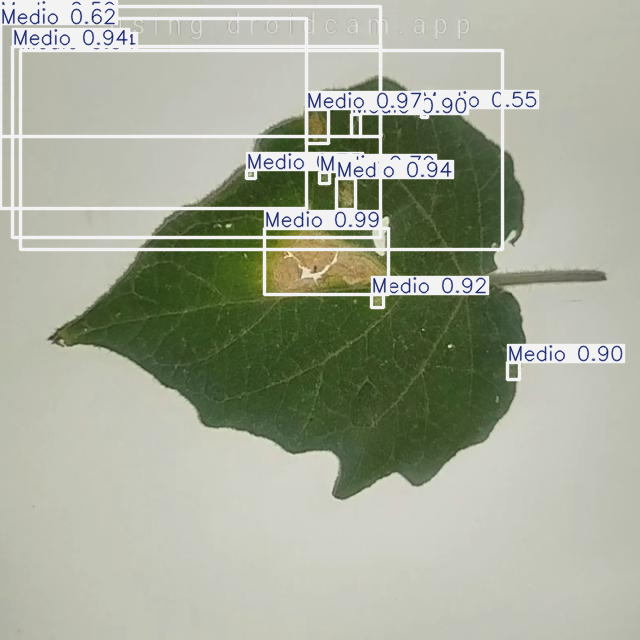

In [ ]:
from ultralytics import YOLO
import glob
import os
from google.colab.patches import cv2_imshow
import cv2

# 1. Cargar el modelo entrenado con tus mejores pesos
model = YOLO('runs/detect/train/weights/best.pt')

# 2. Buscar las imágenes de la carpeta test
test_images = glob.glob('/content/mi_dataset/test/images/*.jpg')

if test_images:
    # Tomar la primera imagen de prueba como ejemplo
    img_path = test_images[0]

    # 3. Hacer la predicción (Inferencia)
    results = model(img_path, conf=0.5) # conf=0.5 ignora detecciones con menos de 50% de certeza

    # 4. Mostrar el resultado visualmente en Colab
    for r in results:
        im_array = r.plot()  # Dibuja los cuadros (bounding boxes) y etiquetas
        cv2_imshow(im_array) # Muestra la imagen en pantalla
else:
    print("No se encontraron imágenes en la ruta de test.")


In [ ]:
# Evaluar el rendimiento general
metrics = model.val()
print(f"Precisión media (mAP50): {metrics.box.map50:.2f}")



Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1421.3±593.8 MB/s, size: 29.8 KB)
val: Scanning /content/mi_dataset/valid/labels.cache... 480 images, 120 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 480/480 167.8Mit/s 0.0s
val: /content/mi_dataset/valid/images/img_027_jpg.rf.992345796870e4651bcd3049420ce661.jpg: 1 duplicate labels removed
val: /content/mi_dataset/valid/images/img_045_jpg.rf.1e9b15f4ca8fe38112977092ae8cd8e7.jpg: 2 duplicate labels removed
val: /content/mi_dataset/valid/images/img_047_jpg.rf.138a690e65485c16f1bc0461ef1856ce.jpg: 1 duplicate labels removed
val: /content/mi_dataset/valid/images/img_058_jpg.rf.7421c6c3f6182ed47c0f66692c4ad7ac.jpg: 1 duplicate labels removed
val: /content/mi_dataset/valid/images/img_065_jpg.rf.e22b36c4874b2867ca2875bf9a58328f.jpg: 1 duplicate labels removed
val: /content/mi_dataset/valid/images/img_068_jpg.rf.86f60c0417bf62df44f7ae7794080595.jpg: 1 duplicate la